In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Import Library

In [1]:
# ==========================================
# IMPORT SEMUA LIBRARY YANG DIBUTUHKAN
# ==========================================
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import os
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import random
import pandas as pd
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight as cw_utils
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

print('Library berhasil diimport')

I0000 00:00:1789054113.807114    6866 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Library berhasil diimport


In [2]:
# ==========================================
# KONFIGURASI
# ==========================================

# Path dataset lokal: folder DATASET berisi subfolder kelas.
PATH_DATASET = Path('DATASET')
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

---
## Load Dataset


In [3]:
# ==========================================
# Load Dataset
# ==========================================
# Mengumpulkan semua path gambar dan label dari empat folder kelas.
image_extensions = {'.jpg'}
data = []

# Define expected_classes as it's used later
expected_classes = ['healthy', 'cocci', 'salmo', 'ncd']

for class_name in expected_classes:
    class_path = PATH_DATASET / class_name
    for img_path in class_path.iterdir():
        if img_path.is_file() and img_path.suffix.lower() in image_extensions:
            data.append({'filepath': str(img_path), 'label': class_name})

df = pd.DataFrame(data)
num_classes = len(df['label'].unique())

# Menampilkan informasi dataset
print(f'Total gambar : {len(df)}')
print(f'Jumlah kelas : {num_classes}')

Total gambar : 6812
Jumlah kelas : 4


---
## Exploratory Data Analysis (EDA)

Analisis distribusi kelas dan visualisasi sampel gambar dari setiap kelas.

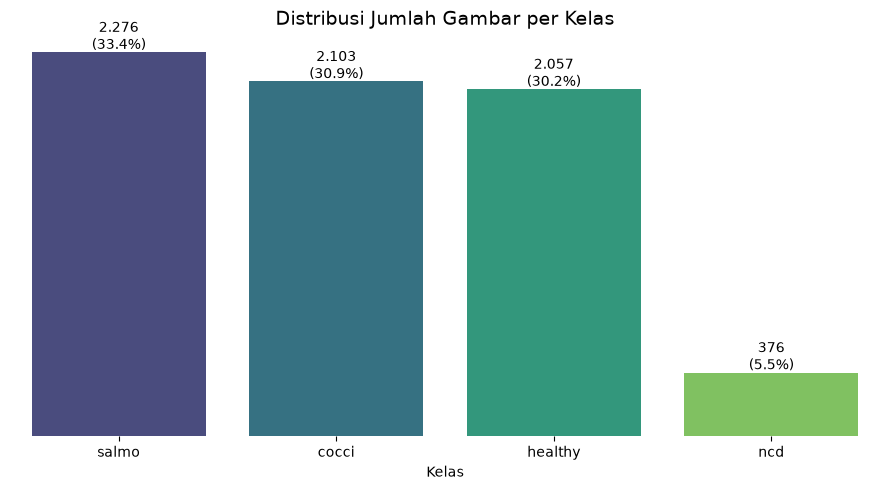

In [4]:
# ==========================================
# DISTRIBUSI KELAS
# ==========================================

# Menghitung jumlah data tiap kelas
class_counts = (df['label'].value_counts().sort_values(ascending=False))

# Menghitung persentase
class_percentages = (class_counts / class_counts.sum() * 100)

plt.figure(figsize=(9, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')

plt.title('Distribusi Jumlah Gambar per Kelas',fontsize=14)
plt.xlabel('Kelas')
plt.ylabel('Jumlah Gambar')

for i, v in enumerate(class_counts.values):
    formatted_value = f"{v:,}".replace(",", ".")
    percentage = class_percentages.iloc[i]
    plt.text(
        i,
        v + 20,
        f'{formatted_value}\n({percentage:.1f}%)',
        ha='center'
    )

sns.despine(
    top=True,
    right=True,
    left=True,
    bottom=True
)

plt.yticks([])
plt.ylabel('')

plt.tight_layout()
plt.show()

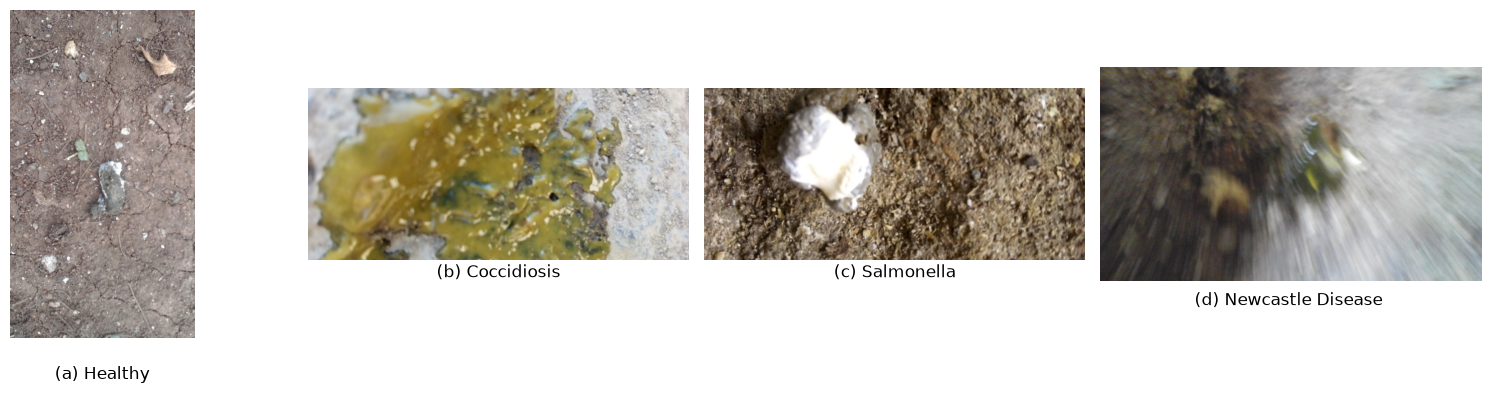

In [5]:
# ==========================================
# VISUALISASI SAMPLE GAMBAR
# ==========================================

categories = {
    'healthy': '(a) Healthy',
    'cocci': '(b) Coccidiosis',
    'salmo': '(c) Salmonella',
    'ncd': '(d) Newcastle Disease '
}

fig, axes = plt.subplots(1, len(categories), figsize=(16, 4))

# fig.suptitle(
#     'Sample Gambar Setiap Kelas',
#     fontsize=16,
#     fontweight='bold'
# )

for i, (class_name, label_caption) in enumerate(categories.items()):

    sample_row = (
        df[df['label'] == class_name]
        .iloc[0]
    )

    img = Image.open(sample_row['filepath']).convert('RGB')

    axes[i].imshow(img)
    axes[i].axis('off')

    axes[i].set_title(
        label_caption,
        fontsize=12,
        y=-0.15
    )

plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# Analisis Sampel Resolusi Tiap Kelas (5 Gambar)
# ==========================================

from PIL import Image
from pathlib import Path
import pandas as pd

resolution_data = []

# Ambil 5 gambar pertama dari setiap kelas
for label in df['label'].unique():

    sample_df = df[df['label'] == label].head(5)

    for _, row in sample_df.iterrows():

        with Image.open(row['filepath']) as img:
            width, height = img.size

        resolution_data.append({
            'Nama File': Path(row['filepath']).name,
            'Label': row['label'],
            'Width (px)': width,
            'Height (px)': height,
            'Resolusi': f'{width} × {height}'
        })

df_resolution_sample = pd.DataFrame(resolution_data)

print(f"Jumlah sampel yang ditampilkan : {len(df_resolution_sample)} gambar")

display(df_resolution_sample)

Jumlah sampel yang ditampilkan : 20 gambar


,Nama File,Label,Width (px),Height (px),Resolusi
0,healthy.0.jpg,healthy,1152,2048,1152 × 2048
1,healthy.1.jpg,healthy,2048,1152,2048 × 1152
2,healthy.10.jpg,healthy,2048,1152,2048 × 1152
3,healthy.100.jpg,healthy,2048,1152,2048 × 1152
4,healthy.1000.jpg,healthy,1152,2048,1152 × 2048
5,cocci.0.jpg,cocci,3200,1440,3200 × 1440
6,cocci.1.jpg,cocci,2448,3264,2448 × 3264
7,cocci.10.jpg,cocci,3200,1440,3200 × 1440
8,cocci.100.jpg,cocci,1440,3200,1440 × 3200
9,cocci.1000.jpg,cocci,3200,1440,3200 × 1440


Ukuran citra asli (Lebar x Tinggi): 2048 x 1152 piksel

--- HASIL EKSTRAKSI NILAI PIKSEL ---
Koordinat Spasial (x,y)  Red (R)  Green (G)  Blue (B)
               (10, 10)       84         76        65
             (512, 288)       50         45        42
            (1024, 576)       89         94        97
           (2028, 1132)      154        171       178


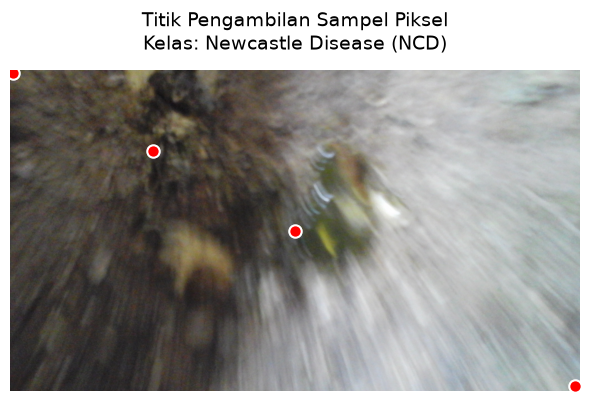

In [7]:
# ==========================================
# EKSTRAKSI SAMPEL NILAI PIKSEL (RGB) MENGGUNAKAN PIL
# ==========================================

# Ambil satu sampel gambar secara otomatis dari DataFrame
# Mengambil filepath dari baris pertama yang memiliki label 'ncd'
sample_row = df[df['label'] == 'ncd'].iloc[0]
image_path = sample_row['filepath']

img_pil = Image.open(image_path).convert('RGB')

# Konversi gambar PIL menjadi Numpy Array agar mudah mengambil titik koordinatnya
img_array = np.array(img_pil)

# Dapatkan ukuran gambar (Tinggi, Lebar, Kanal)
tinggi, lebar, kanal = img_array.shape
print(f"Ukuran citra asli (Lebar x Tinggi): {lebar} x {tinggi} piksel")

# Tentukan beberapa titik koordinat (x, y)
koordinat_sampel = [
    (10, 10),                            # Sudut kiri atas
    (lebar // 4, tinggi // 4),           # Area tengah atas
    (lebar // 2, tinggi // 2),           # Tepat di tengah gambar
    (lebar - 20, tinggi - 20)            # Sudut kanan bawah
]

# Ekstrak nilai RGB pada koordinat tersebut
data_piksel = []

for x, y in koordinat_sampel:
    # Array citra numpy diakses dengan format matriks: array[baris, kolom] -> array[y, x]
    r, g, b = img_array[y, x]

    data_piksel.append({
        "Koordinat Spasial (x,y)": f"({x}, {y})",
        "Red (R)": r,
        "Green (G)": g,
        "Blue (B)": b
    })

# Tampilkan ke dalam bentuk Tabel (DataFrame)
df_piksel = pd.DataFrame(data_piksel)
print("\n--- HASIL EKSTRAKSI NILAI PIKSEL ---")
print(df_piksel.to_string(index=False))

# Visualisasi gambar beserta titik sampel
plt.figure(figsize=(6, 6))
plt.imshow(img_array)

# Menandai titik koordinat dengan lingkaran merah bergaris putih agar terlihat kontras
for x, y in koordinat_sampel:
    plt.scatter(x, y, color='red', s=80, edgecolor='white', linewidth=1.5, zorder=5)

plt.title("Titik Pengambilan Sampel Piksel\nKelas: Newcastle Disease (NCD)", fontsize=14, pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

In [8]:
# ==========================================
# MEMBUAT TABEL SELURUH NILAI PIKSEL
# ==========================================

data_semua_piksel = []

for y in range(tinggi):
    for x in range(lebar):
        r, g, b = img_array[y, x]

        data_semua_piksel.append({
            "x": x,
            "y": y,
            "R": int(r),
            "G": int(g),
            "B": int(b)
        })

df_semua_piksel = pd.DataFrame(data_semua_piksel)

print("\nJumlah piksel :", len(df_semua_piksel))
display(df_semua_piksel)


Jumlah piksel : 2359296


,x,y,R,G,B
0,0,0,79,77,65
1,1,0,78,76,64
2,2,0,79,77,64
3,3,0,81,79,66
4,4,0,81,79,64
...,...,...,...,...,...
2359291,2043,1151,170,179,186
2359292,2044,1151,169,178,183
2359293,2045,1151,167,178,182
2359294,2046,1151,163,177,178


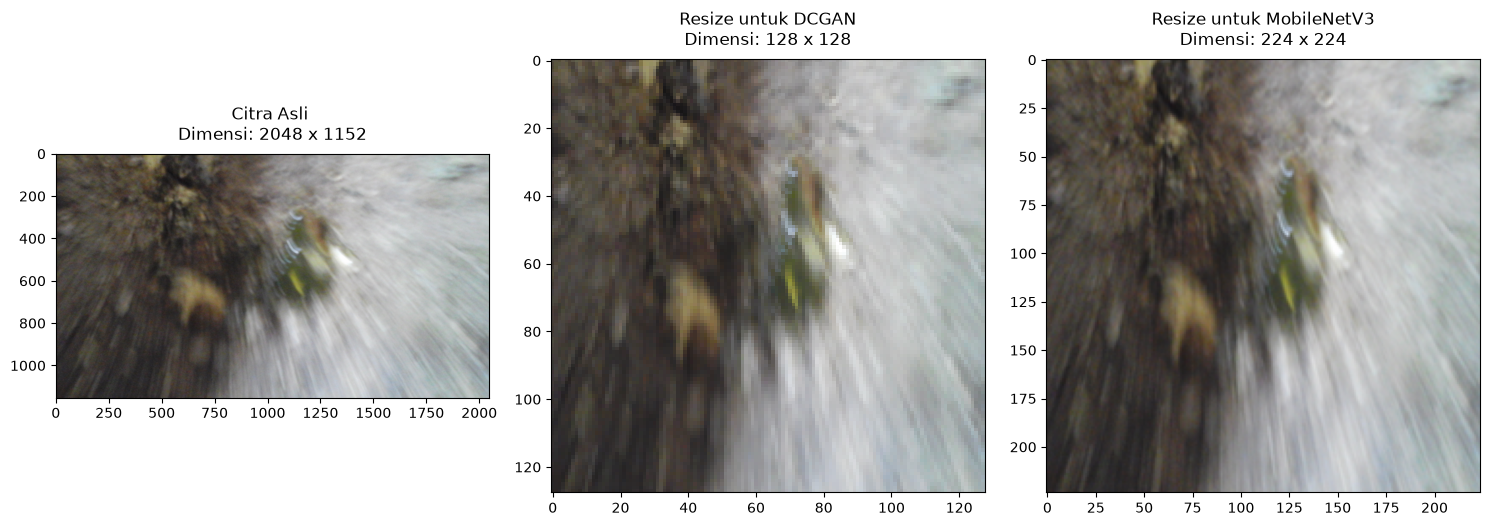

In [9]:
# ==========================================
# VISUALISASI SEBELUM DAN SESUDAH RESIZE
# ==========================================
import matplotlib.pyplot as plt
from PIL import Image

# 1. Ambil 1 sampel gambar NCD
sample_row = df[df['label'] == 'ncd'].iloc[0]
img_original = Image.open(sample_row['filepath']).convert('RGB')
lebar_asli, tinggi_asli = img_original.size

# 2. Lakukan proses Resize (Simulasi)
img_dcgan = img_original.resize((128, 128))       # Untuk DCGAN
img_mobilenet = img_original.resize((224, 224))   # Untuk MobileNetV3

# 3. Visualisasikan secara berdampingan
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot Citra Asli
axes[0].imshow(img_original)
axes[0].set_title(f"Citra Asli \nDimensi: {lebar_asli} x {tinggi_asli}", fontsize=12, pad=10)
axes[0].axis('on') # Biarkan sumbu menyala agar rasio panjang x lebar terlihat

# Plot Citra Resize DCGAN
axes[1].imshow(img_dcgan)
axes[1].set_title("Resize untuk DCGAN\nDimensi: 128 x 128", fontsize=12, pad=10)
axes[1].axis('on')

# Plot Citra Resize MobileNetV3
axes[2].imshow(img_mobilenet)
axes[2].set_title("Resize untuk MobileNetV3\nDimensi: 224 x 224", fontsize=12, pad=10)
axes[2].axis('on')

plt.tight_layout()
plt.show()

## Preprocessing Data

### Split Dataset (80% data latih dan 20% data uji)

In [10]:
# ==========================================
# Split Dataset
# ==========================================

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df['label']
)

# Mengatur ulang indeks DataFrame
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

total_data = len(df)

print("Hasil Pembagian Dataset")
print("=" * 40)
print(f"Total data : {total_data}")
print(f"Data latih : {len(train_df)} "f"({len(train_df) / total_data:.2%})")
print(f"Data uji   : {len(test_df)} "f"({len(test_df) / total_data:.2%})")

Hasil Pembagian Dataset
Total data : 6812
Data latih : 5449 (79.99%)
Data uji   : 1363 (20.01%)


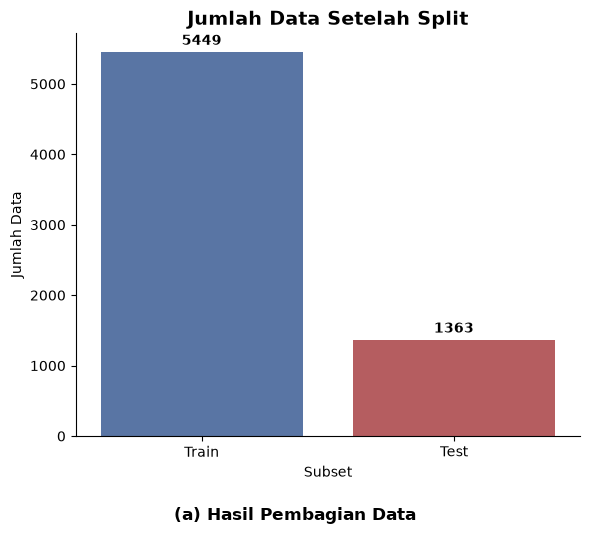

In [11]:
# ==========================================
# VISUALISASI HASIL SPLIT DATASET
# ==========================================

# ==========================================
# MENYIAPKAN DATA VISUALISASI SPLIT
# ==========================================

split_counts = pd.concat(
    [
        train_df['label'].value_counts().rename('Train'),
        test_df['label'].value_counts().rename('Test')
    ],
    axis=1
).reindex(expected_classes).fillna(0).astype(int)

split_summary = pd.DataFrame({
    'Subset': ['Train', 'Test'],
    'Jumlah Data': [len(train_df), len(test_df)]
})

# ==========================================
# GRAFIK JUMLAH DATA PER SUBSET
# ==========================================

plt.figure(figsize=(6,5))

ax = sns.barplot(
    data=split_summary,
    x='Subset',
    y='Jumlah Data',
    palette=['#4C72B0', '#C44E52']
)

plt.title('Jumlah Data Setelah Split', fontsize=14, fontweight='bold')
plt.figtext(
    0.5, -0.05,
    '(a) Hasil Pembagian Data',
    ha='center',
    fontsize=12,
    fontweight='bold'
)

ax.set_xlabel('Subset')
ax.set_ylabel('Jumlah Data')

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%d',
        fontweight='bold',
        padding=3
    )

sns.despine()
plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

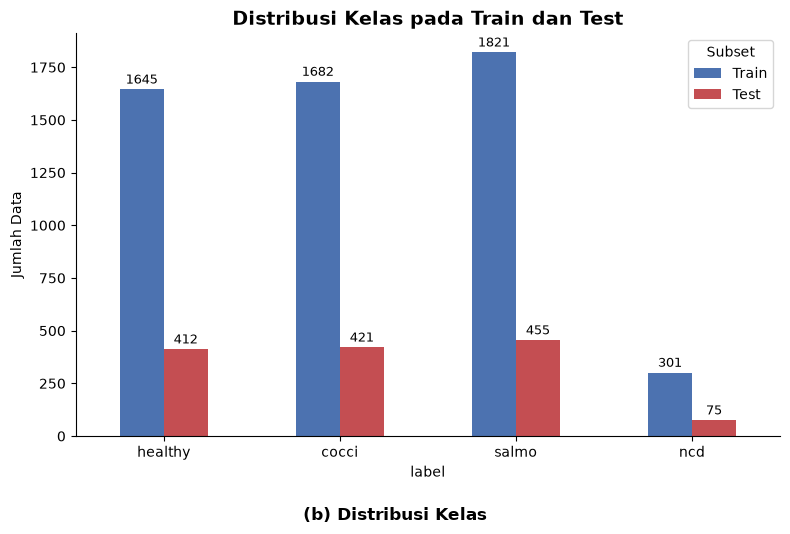

In [13]:
# ==========================================
# GRAFIK DISTRIBUSI KELAS
# ==========================================

plt.figure(figsize=(8,5))

ax = split_counts.plot(
    kind='bar',
    color=['#4C72B0', '#C44E52'],
    figsize=(8,5)
)

plt.title('Distribusi Kelas pada Train dan Test',
          fontsize=14, fontweight='bold')
plt.figtext(
    0.5, -0.05,
    '(b) Distribusi Kelas',
    ha='center',
    fontsize=12,
    fontweight='bold'
)

ax.set_ylabel('Jumlah Data')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Subset')

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%d',
        fontsize=9,
        padding=2
    )

sns.despine()
plt.tight_layout()
plt.show()

In [13]:
display(split_counts)

,Train,Test
label,,
healthy,1645,412
cocci,1682,421
salmo,1821,455
ncd,301,75


In [14]:
# ==========================================
# INISIALISASI IMAGE DATA GENERATOR
# NORMALISASI PIXEL KE RENTANG -1 HINGGA 1
# ==========================================

# Fungsi normalisasi:
# nilai piksel awal 0–255 diubah menjadi -1–1
def normalize_to_minus_one_one(image):
    return (image / 127.5) - 1.0


train_datagen = ImageDataGenerator(
    preprocessing_function=normalize_to_minus_one_one
)

# Data uji menggunakan preprocessing yang sama
test_datagen = ImageDataGenerator(
    preprocessing_function=normalize_to_minus_one_one
)

print("Membuat generator data...")

# ==========================================
# GENERATOR DATA LATIH
# ==========================================

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=expected_classes,
    shuffle=True,
    seed=SEED
)

# ==========================================
# GENERATOR DATA UJI
# ==========================================

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=expected_classes,
    shuffle=False
)


# ==========================================
# MENAMPILKAN LABEL DAN ONE-HOT ENCODING
# ==========================================

print("\n--- Contoh One-Hot Encoding per Kelas ---")

for class_name in expected_classes:
    class_index = test_generator.class_indices[class_name]

    one_hot_vector = to_categorical(
        class_index,
        num_classes=len(expected_classes)
    )

    print(f"Class   : {class_name}")
    print(f"Index   : {class_index}")
    print(f"One-Hot : {one_hot_vector}")
    print()


print("Class Labels dari generator.class_indices:")

for label, index in test_generator.class_indices.items():
    print(f"  {label}: {index}")

Membuat generator data...
Found 5449 validated image filenames belonging to 4 classes.
Found 1363 validated image filenames belonging to 4 classes.

--- Contoh One-Hot Encoding per Kelas ---
Class   : healthy
Index   : 0
One-Hot : [1. 0. 0. 0.]

Class   : cocci
Index   : 1
One-Hot : [0. 1. 0. 0.]

Class   : salmo
Index   : 2
One-Hot : [0. 0. 1. 0.]

Class   : ncd
Index   : 3
One-Hot : [0. 0. 0. 1.]

Class Labels dari generator.class_indices:
  healthy: 0
  cocci: 1
  salmo: 2
  ncd: 3


In [15]:
def cek_batch_generator(generator, nama="Generator"):
    generator.reset()
    batch_x, batch_y = next(generator)

    print(f"{nama}")
    print(f"  shape batch_x : {batch_x.shape}")
    print(f"  min           : {batch_x.min():.6f}")
    print(f"  max           : {batch_x.max():.6f}")
    print(f"  mean          : {batch_x.mean():.6f}")
    print(f"  sample pixel  : {batch_x[0, 0, 0]}")
    print()

cek_batch_generator(train_generator, "Train Generator")
cek_batch_generator(test_generator, "Test Generator")

Train Generator
  shape batch_x : (32, 224, 224, 3)
  min           : -1.000000
  max           : 1.000000
  mean          : 0.194028
  sample pixel  : [-0.73333335 -0.8352941  -0.90588236]

Test Generator
  shape batch_x : (32, 224, 224, 3)
  min           : -1.000000
  max           : 1.000000
  mean          : 0.124790
  sample pixel  : [-0.7019608  -0.12156862  0.07450986]



In [16]:
# ==========================================
# MEMERIKSA HASIL NORMALISASI
# ==========================================

train_generator.reset()

batch_images, batch_labels = next(train_generator)

print("Shape batch citra :", batch_images.shape)
print("Shape batch label :", batch_labels.shape)

print("\nRentang nilai piksel setelah normalisasi:")
print("Nilai minimum :", batch_images.min())
print("Nilai maksimum:", batch_images.max())
print("Nilai rata-rata:", batch_images.mean())

print("\nContoh nilai piksel RGB:")
print(batch_images[0, 0, 0])

Shape batch citra : (32, 224, 224, 3)
Shape batch label : (32, 4)

Rentang nilai piksel setelah normalisasi:
Nilai minimum : -1.0
Nilai maksimum: 1.0
Nilai rata-rata: 0.12506852

Contoh nilai piksel RGB:
[-0.29411763 -0.34117645 -0.34117645]


## Pemodelan

In [17]:
# ==========================================
# MEMBANGUN ARSITEKTUR MODEL
# ==========================================
base_model = MobileNetV3Small(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3),
    include_preprocessing=False
)

# Freeze backbone
base_model.trainable = False

# Classifier head
x = base_model.output
x = GlobalAveragePooling2D()(x)
predictions = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

print('Backbone MobileNetV3Small dibekukan; classifier head tetap dilatih.')

I0000 00:00:1785681661.008882    5148 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Backbone MobileNetV3Small dibekukan; classifier head tetap dilatih.


In [18]:
def cek_setelah_preprocessing_mobilenet(model, generator):
    generator.reset()
    batch_x, _ = next(generator)

    rescaling_layers = [
        layer for layer in model.layers
        if isinstance(layer, tf.keras.layers.Rescaling)
    ]

    if not rescaling_layers:
        print("Tidak ada layer Rescaling di model.")
        print("Kemungkinan include_preprocessing=False.")
        return

    rescaling_layer = rescaling_layers[0]

    preprocessing_model = tf.keras.Model(
        inputs=model.input,
        outputs=rescaling_layer.output
    )

    hasil = preprocessing_model.predict(batch_x, verbose=0)

    print("Setelah preprocessing internal MobileNetV3")
    print(f"  layer         : {rescaling_layer.name}")
    print(f"  shape         : {hasil.shape}")
    print(f"  min           : {hasil.min():.6f}")
    print(f"  max           : {hasil.max():.6f}")
    print(f"  mean          : {hasil.mean():.6f}")
    print(f"  sample pixel  : {hasil[0, 0, 0]}")

cek_setelah_preprocessing_mobilenet(model, train_generator)

Tidak ada layer Rescaling di model.
Kemungkinan include_preprocessing=False.


In [19]:
# ==========================================
# RINGKASAN MODEL
# ==========================================
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 113, 113,  │          0 │ activation[0][0]  │
│ (ZeroPadding2D)     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 56, 56,    │        144 │ expanded_conv_de… │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 56, 56,    │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 56, 56,    │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │          0 │ re_lu[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │        136 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 8)   │          0 │ expanded_conv_sq… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 1, 1, 16)  │        144 │ expanded_conv_sq… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1, 1, 16)  │          0 │ expanded_conv_sq… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 1, 1, 16)  │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 1, 1, 16)  │          0 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_sque… │ (None, 56, 56,    │          0 │ re_lu[0][0],      │
│ (Multiply)          │ 16)               │            │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 56, 56,    │        256 │ expanded_conv_sq… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 56, 56,    │         64 │ expanded_conv_pr

 Total params: 941,428 (3.59 MB)

 Trainable params: 2,308 (9.02 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [ ]:
# ==========================================
# PELATIHAN MODEL
# ==========================================

EPOCHS = 10
LEARNING_RATE = 0.0001

# ==========================================
# COMPILE MODEL
# ==========================================

optimizer = Adam(
    learning_rate=LEARNING_RATE
)

model.compile(
    loss='categorical_crossentropy',
    optimizer=optimizer,
    metrics=[
        tf.keras.metrics.F1Score(
            average='macro',
            name='f1_score'
        )
    ]
)


In [21]:
# Agar urutan generator dimulai kembali dari batch pertama
train_generator.reset()

print("Memulai Pelatihan Model...")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    verbose=1
)

# ==========================================
# DIREKTORI PENYIMPANAN MODEL
# ==========================================

MODEL_SAVE_DIR = Path('model_outputs/MobileNetV3_Baseline')
MODEL_SAVE_DIR.mkdir(parents=True,exist_ok=True)
MODEL_SAVE_PATH = (MODEL_SAVE_DIR /'model_baseline_final.keras')


# ==========================================
# MENYIMPAN MODEL AKHIR
# ==========================================
model.save(MODEL_SAVE_PATH)

print("Training selesai!")
print("Model berhasil disimpan di:")
print(MODEL_SAVE_PATH)

Memulai Pelatihan Model...
Epoch 1/10


I0000 00:00:1785681672.155168    5148 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1785681681.676419    5895 service.cc:153] XLA service 0x706444032430 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785681681.676492    5895 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1785681682.075541    5895 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785681684.356143    5895 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1785681684.601193    5895 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8050__.150


  1/171 ━━━━━━━━━━━━━━━━━━━━ 3:30:05 74s/step - f1_score: 0.1177 - loss: 2.5023

I0000 00:00:1785681746.101999    5895 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1785681748.373816    5896 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8050__.150


171/171 ━━━━━━━━━━━━━━━━━━━━ 481s 2s/step - f1_score: 0.3868 - loss: 1.4078
Epoch 2/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 294s 2s/step - f1_score: 0.7338 - loss: 0.7660
Epoch 3/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 277s 2s/step - f1_score: 0.8242 - loss: 0.5511
Epoch 4/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 286s 2s/step - f1_score: 0.8582 - loss: 0.4435
Epoch 5/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 304s 2s/step - f1_score: 0.8834 - loss: 0.3777
Epoch 6/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 413s 2s/step - f1_score: 0.8993 - loss: 0.3324
Epoch 7/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 462s 3s/step - f1_score: 0.9114 - loss: 0.2986
Epoch 8/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 451s 3s/step - f1_score: 0.9205 - loss: 0.2726
Epoch 9/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 278s 2s/step - f1_score: 0.9288 - loss: 0.2516
Epoch 10/10
171/171 ━━━━━━━━━━━━━━━━━━━━ 414s 2s/step - f1_score: 0.9319 - loss: 0.2343
Training selesai!
Model berhasil disimpan di:
model_outputs/MobileNetV3_Baseline/model_baseline_final.keras


In [22]:
# # ==========================================
# # LOAD MODEL YANG SUDAH DILATIH
# # ==========================================

# import tensorflow as tf

# # Path model yang sudah disimpan
# MODEL_PATH = "/content/drive/MyDrive/PROKSI/Program/weighted_f1score/model_baseline_terbaik.keras"
# # Jika kamu menyimpan dengan format .h5, gunakan:
# # MODEL_PATH = "/content/drive/MyDrive/model_mobilenetv3_baseline.h5"

# # Load model
# model = tf.keras.models.load_model(MODEL_PATH)

# print("Model berhasil dimuat kembali.")
# model.summary()

---
## Evaluasi

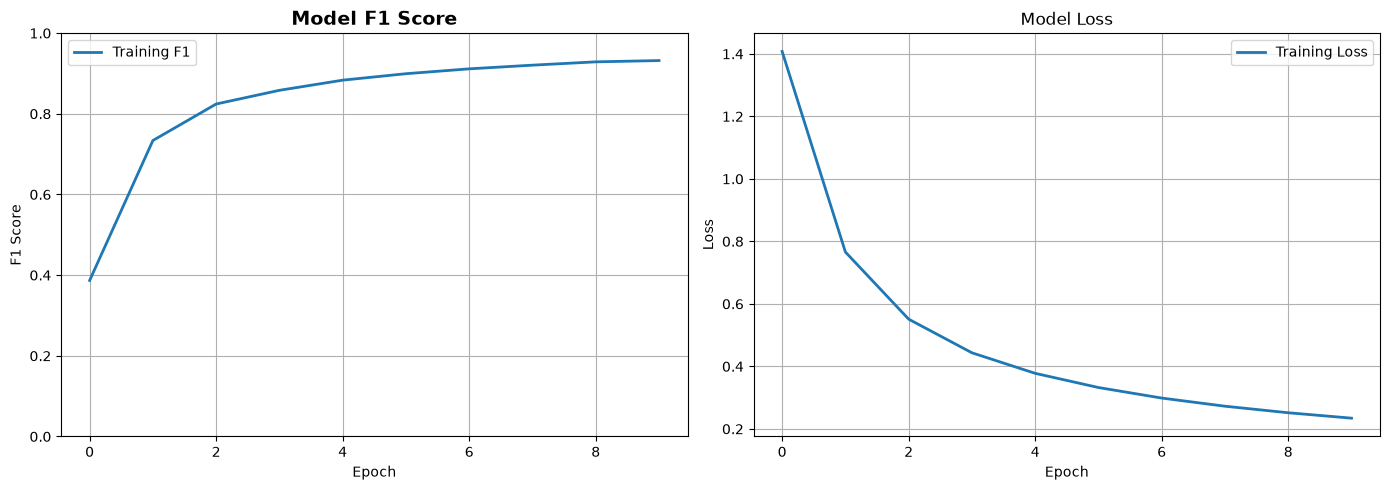

In [23]:
# ==========================================
# LEARNING CURVE
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# F1 Score
ax1.plot(history.history['f1_score'], label='Training F1', linewidth=2)
ax1.set_title('Model F1 Score', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('F1 Score')
ax1.set_ylim(0, 1)
ax1.legend()
ax1.grid(True)

# Loss
ax2.plot(history.history['loss'], label='Training Loss', linewidth=2)
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# EVALUASI PADA DATA TEST
# ==========================================
print("Mengevaluasi model pada data test...\n")

test_generator.reset()
test_loss, f1_score = model.evaluate(test_generator, verbose=1)

print(f"\nTest Loss    : {test_loss:.4f}")
print(f"Test F1 Score: {f1_score:.4f} ({f1_score:.2%})")

Mengevaluasi model pada data test...

43/43 ━━━━━━━━━━━━━━━━━━━━ 643s 15s/step - f1_score: 0.9379 - loss: 0.2245

Test Loss    : 0.2245
Test F1 Score: 0.9379 (93.79%)


43/43 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step


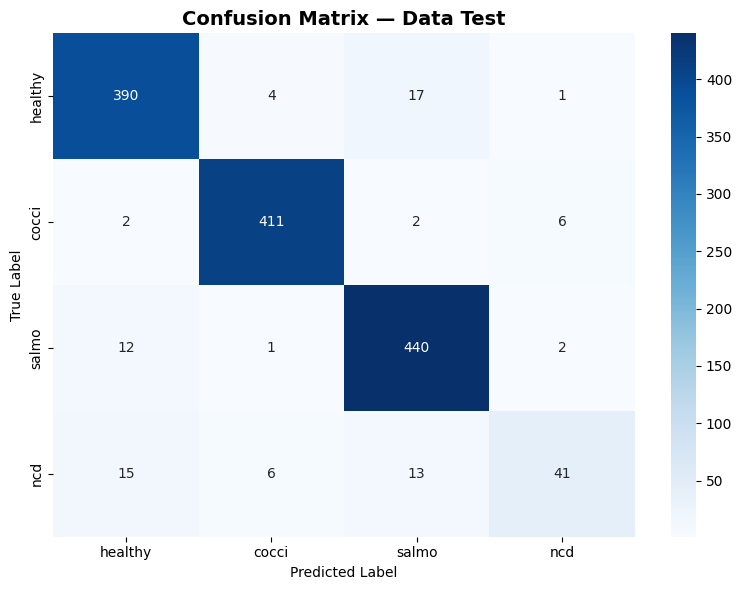

In [ ]:
# ==========================================
# CONFUSION MATRIX
# ==========================================
test_generator.reset()
y_pred_probs = model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title('Confusion Matrix — Data Test', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# CLASSIFICATION REPORT
# ==========================================
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels, digits=4))

Classification Report:

              precision    recall  f1-score   support

     healthy     0.9308    0.9466    0.9386       412
       cocci     0.9739    0.9762    0.9751       421
       salmo     0.9322    0.9670    0.9493       455
         ncd     0.8200    0.5467    0.6560        75

    accuracy                         0.9406      1363
   macro avg     0.9142    0.8591    0.8798      1363
weighted avg     0.9385    0.9406    0.9379      1363



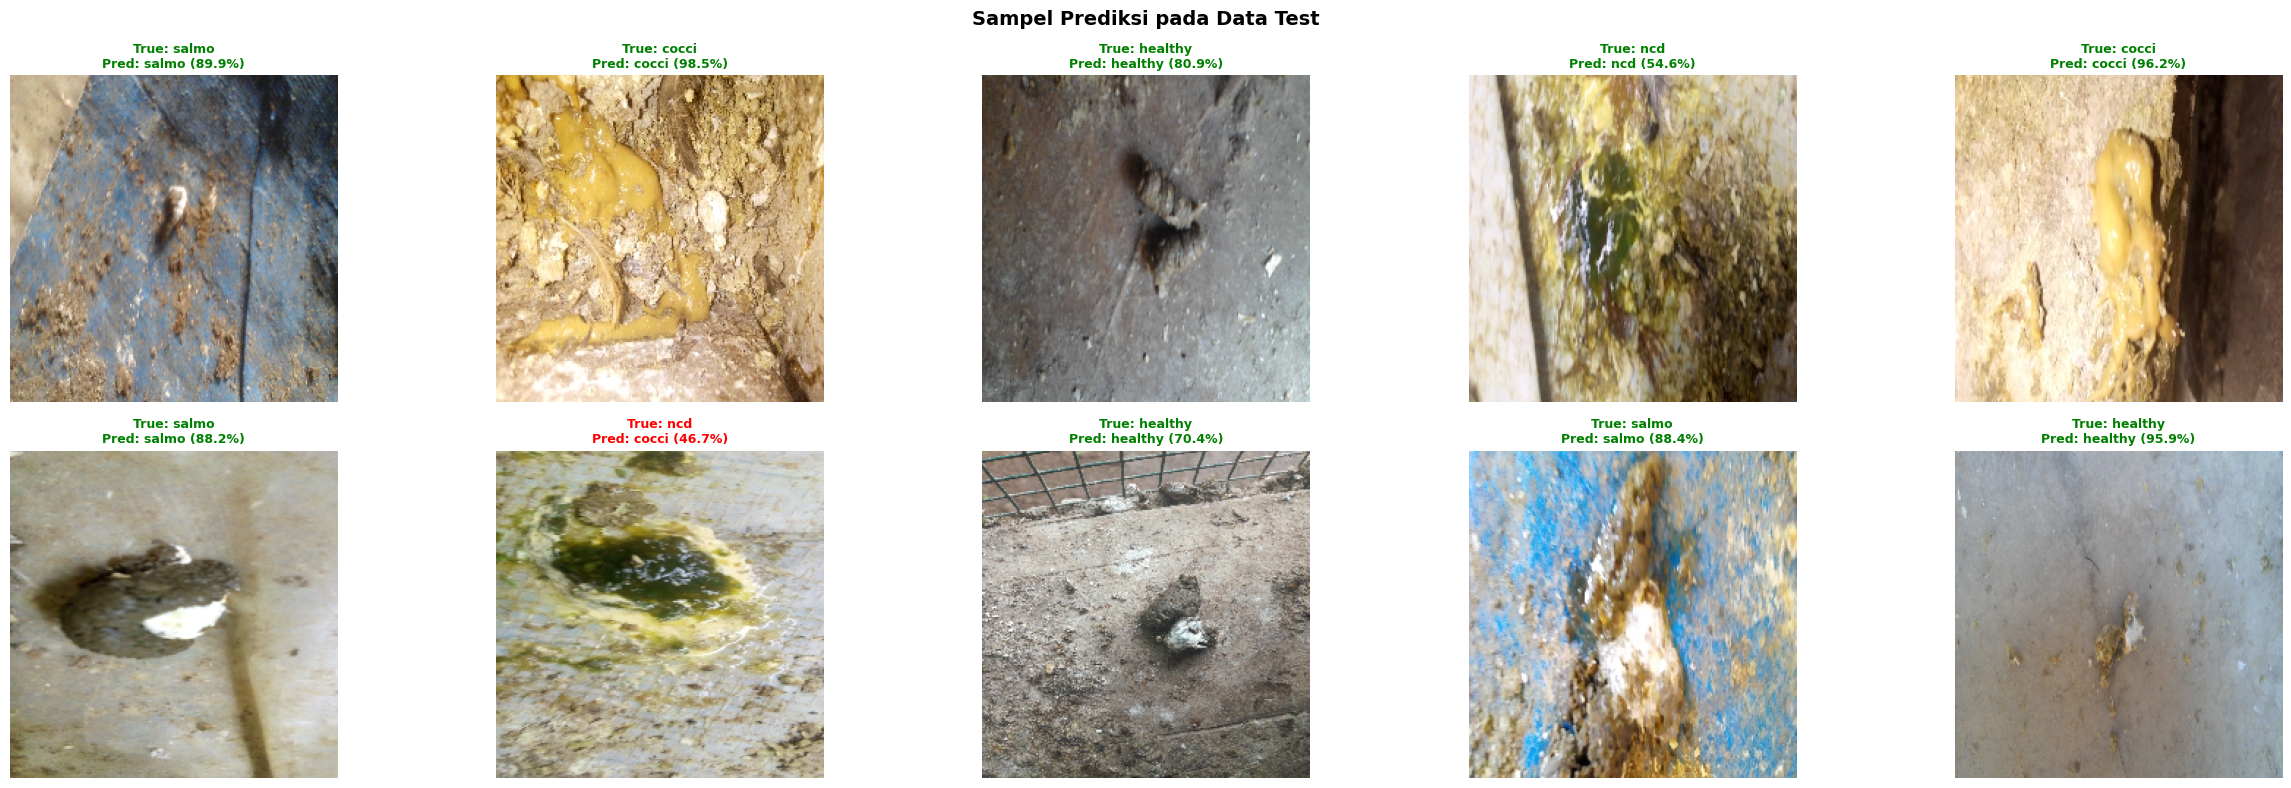

In [ ]:
# ==========================================
# VISUALISASI PREDIKSI SAMPEL
# ==========================================
test_generator.reset()
sample_batch_x, sample_batch_y = next(test_generator)
sample_preds = model.predict(sample_batch_x, verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(25, 8))
for i, ax in enumerate(axes.flat):
    if i >= len(sample_batch_x):
        break

    img_show = sample_batch_x[i]

    if img_show.min() < 0:
        img_show = (img_show + 1) / 2
    elif img_show.max() > 1:
        img_show = img_show / 255.0

    ax.imshow(img_show)
    true_label = class_labels[np.argmax(sample_batch_y[i])]
    pred_label = class_labels[np.argmax(sample_preds[i])]
    confidence = np.max(sample_preds[i]) * 100
    color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f'True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)',
                 fontsize=9, color=color, fontweight='bold')
    ax.axis('off')

plt.suptitle('Sampel Prediksi pada Data Test', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

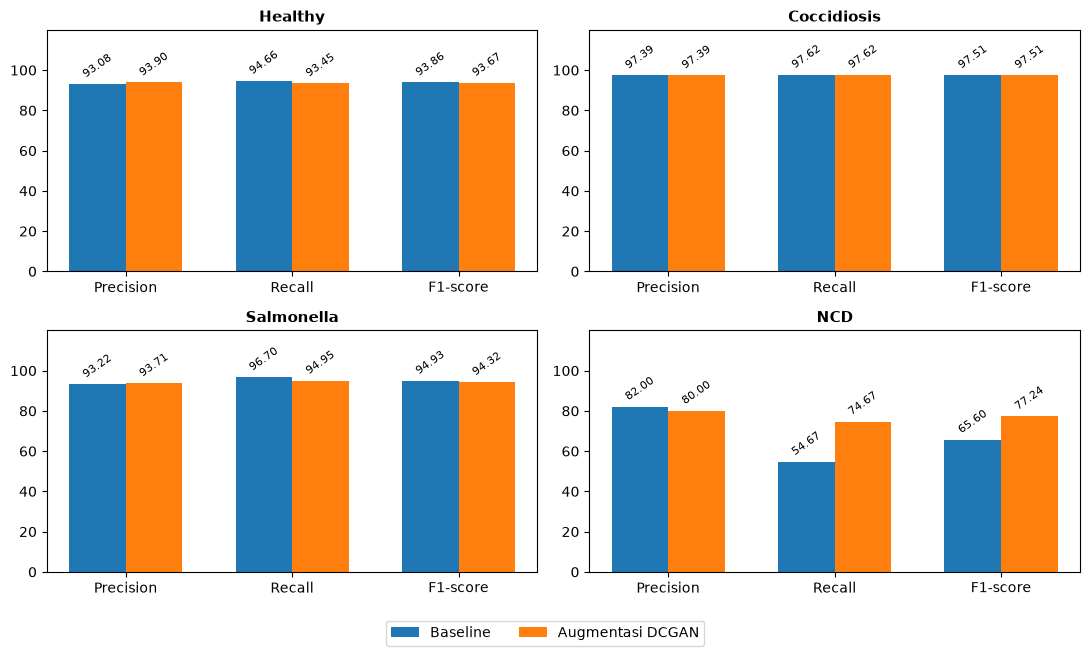

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Nilai metrik (%) hasil pengujian pada data uji yang sama.
classes = ['Healthy', 'Coccidiosis', 'Salmonella', 'NCD']
metrics = ['Precision', 'Recall', 'F1-score']

baseline = {
    'Coccidiosis': [97.39, 97.62, 97.51],
    'Healthy': [93.08, 94.66, 93.86],
    'NCD': [82.00, 54.67, 65.60],
    'Salmonella': [93.22, 96.70, 94.93],
}

dcgan = {
    'Coccidiosis': [97.39, 97.62, 97.51],
    'Healthy': [93.90, 93.45, 93.67],
    'NCD': [80.00, 74.67, 77.24],
    'Salmonella': [93.71, 94.95, 94.32],
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)


x = np.arange(len(metrics))
width = 0.34
colors = {'Baseline': '#1f77b4', 'DCGAN': '#ff7f0e'}

for ax, kelas in zip(axes.flat, classes):
    nilai_baseline = baseline[kelas]
    nilai_dcgan = dcgan[kelas]
    bars1 = ax.bar(x - width / 2, nilai_baseline, width,
                   label='Baseline', color=colors['Baseline'])
    bars2 = ax.bar(x + width / 2, nilai_dcgan, width,
                   label='Augmentasi DCGAN', color=colors['DCGAN'])

    ax.set_title(kelas, fontsize=11, fontweight='bold')
    ax.set_xticks(x, metrics)
    ax.set_ylim(0, 120)
    ax.set_yticks(np.arange(0, 101, 20))
    ax.grid(False)  # Tampilan lebih bersih tanpa garis kisi.

    for bars in (bars1, bars2):
        for bar in bars:
            value = bar.get_height()
            ax.annotate(f'{value:.2f}',
                        (bar.get_x() + bar.get_width() / 2, value),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=8, rotation=35)


# Menampilkan label skala 0--100 pada sisi kiri setiap grafik di kolom kanan.
for ax in axes[:, 1]:
    ax.tick_params(axis='y', labelleft=True, labelright=False, left=True, right=False)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2,
           frameon=True, bbox_to_anchor=(0.5, 0.01))
fig.tight_layout(rect=[0, 0.07, 1, 0.95])


plt.show()

